# 01. Auditoría de datos y análisis exploratorio (EDA)

**Proyecto:** Estimación de incidencia acumulada de fallecimiento en pacientes con cirrosis, considerando el trasplante como evento competitivo.

Este notebook carga el conjunto oficial de UCI, valida su estructura y genera las tablas y figuras necesarias para el informe. No entrena modelos predictivos.

**Decisión metodológica:** `Status` no se reduce a una clasificación binaria. Se conservan las tres circunstancias: `D` = fallecimiento, `C` = censura durante el seguimiento y `CL` = trasplante.

Ejecute las celdas en orden. La primera descarga puede requerir conexión a internet.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Abra Jupyter desde la carpeta raíz Proyecto_Cirrosis_Supervivencia.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.cirrhosis_data import load_cirrhosis_data, normalize_status, clinical_predictors, survival_outcomes

TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: C:\Archivos de Proyectos\B - Archivos de Proyectos Python\Proyecto Catedra - ACD104 - Predicción Cirrosis


## 1. Carga del conjunto de datos

In [2]:
df = load_cirrhosis_data()
print(f"Registros: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]:,}")
display(df.head())
print("Columnas:", list(df.columns))
print("Fuente: UCI Machine Learning Repository, conjunto 878.")

Registros: 418
Columnas: 21


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,...,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Triglycerides,Platelets,Prothrombin,Stage,Status_label
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,...,261,2.60,156,1718.0,137.95,172,190,12.2,4.0,D
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,...,302,4.14,54,7394.8,113.52,88,221,10.6,3.0,C
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,...,176,3.48,210,516.0,96.10,55,151,12.0,4.0,D
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,...,244,2.54,64,6121.8,60.63,92,183,10.3,4.0,D
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,...,279,3.53,143,671.0,113.15,72,136,10.9,3.0,CL


Columnas: ['ID', 'N_Days', 'Status', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Triglycerides', 'Platelets', 'Prothrombin', 'Stage', 'Status_label']
Fuente: UCI Machine Learning Repository, conjunto 878.


## 2. Auditoría de estructura y calidad

In [3]:
raw_df = df.drop(columns=["Status_label"], errors="ignore")
audit = pd.DataFrame({
    "variable": raw_df.columns.astype(str),
    "tipo": [str(raw_df[c].dtype) for c in raw_df.columns],
    "n_faltantes": [int(raw_df[c].isna().sum()) for c in raw_df.columns],
    "pct_faltantes": [float(raw_df[c].isna().mean() * 100) for c in raw_df.columns],
    "n_valores_unicos": [int(raw_df[c].nunique(dropna=True)) for c in raw_df.columns],
})
audit = audit.sort_values(["pct_faltantes", "variable"], ascending=[False, True])
display(audit)
audit.to_csv(TABLES / "auditoria_calidad.csv", index=False, encoding="utf-8-sig")

n_duplicates = int(raw_df.duplicated().sum())
if "ID" in df.columns:
    duplicate_ids = int(df["ID"].duplicated().sum())
else:
    duplicate_ids = np.nan
summary = pd.DataFrame([{
    "registros": len(raw_df),
    "columnas": len(raw_df.columns),
    "filas_duplicadas_exactas": n_duplicates,
    "identificadores_ID_duplicados": duplicate_ids,
    "n_faltantes_total": int(raw_df.isna().sum().sum()),
}])
display(summary)
summary.to_csv(TABLES / "resumen_cohorte.csv", index=False, encoding="utf-8-sig")

,variable,tipo,n_faltantes,pct_faltantes,n_valores_unicos
14,Alk_Phos,float64,106,25.358852,295
11,Cholesterol,object,106,25.358852,202
13,Copper,object,106,25.358852,159
15,SGOT,float64,106,25.358852,179
16,Triglycerides,object,106,25.358852,147
6,Ascites,object,105,25.119617,3
3,Drug,object,105,25.119617,3
7,Hepatomegaly,object,105,25.119617,3
8,Spiders,object,105,25.119617,3
17,Platelets,object,7,1.674641,244


,registros,columnas,filas_duplicadas_exactas,identificadores_ID_duplicados,n_faltantes_total
0,418,20,0,0,965


## 3. Distribución del estado de seguimiento

,Status,n,porcentaje,significado
0,C,232,55.502392,Censura: fallecimiento no observado durante el...
1,D,161,38.516746,Fallecimiento observado
2,CL,25,5.980861,Trasplante hepático


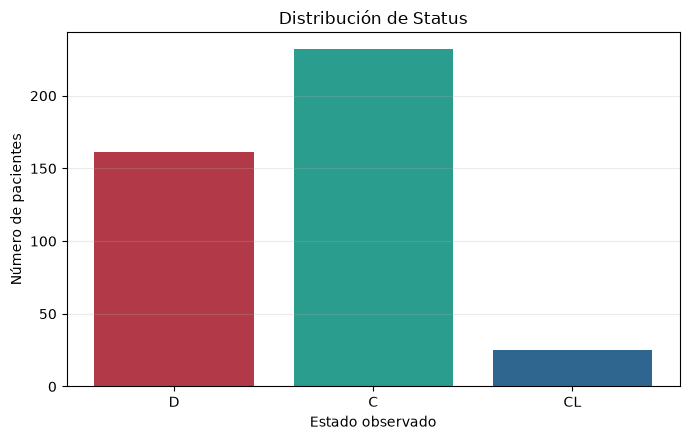

In [4]:
status_counts = (
    df["Status_label"].value_counts(dropna=False)
      .rename_axis("Status")
      .reset_index(name="n")
)
status_counts["porcentaje"] = status_counts["n"] / status_counts["n"].sum() * 100
status_counts["significado"] = status_counts["Status"].map({
    "D": "Fallecimiento observado",
    "C": "Censura: fallecimiento no observado durante el seguimiento",
    "CL": "Trasplante hepático",
})
display(status_counts)
status_counts.to_csv(TABLES / "frecuencias_status.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(7, 4.5))
order = [x for x in ["D", "C", "CL"] if x in status_counts["Status"].values]
plot_counts = status_counts.set_index("Status").reindex(order)
ax.bar(plot_counts.index, plot_counts["n"], color=["#B23A48", "#2A9D8F", "#2F6690"][:len(order)])
ax.set(title="Distribución de Status", xlabel="Estado observado", ylabel="Número de pacientes")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES / "eda_01_distribucion_status.png", dpi=180)
plt.show()

## 4. Valores faltantes

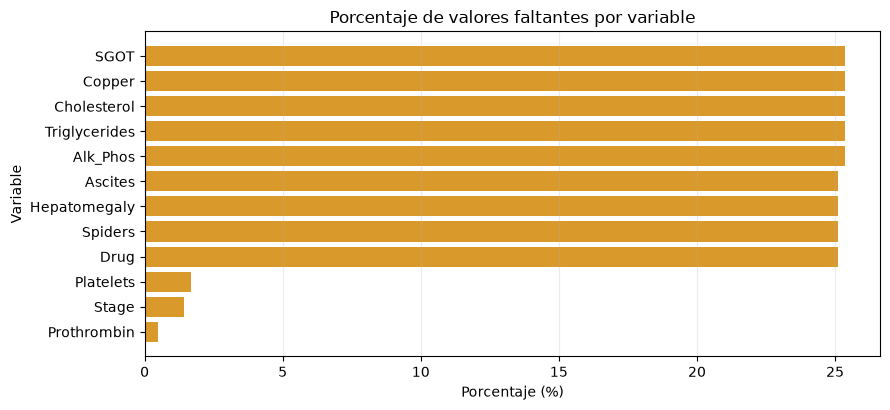

In [5]:
missing = audit.loc[audit["n_faltantes"] > 0].sort_values("pct_faltantes", ascending=True)
if missing.empty:
    print("No se detectaron valores faltantes en la carga actual.")
else:
    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(missing))))
    ax.barh(missing["variable"], missing["pct_faltantes"], color="#D99A2B")
    ax.set(title="Porcentaje de valores faltantes por variable", xlabel="Porcentaje (%)", ylabel="Variable")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIGURES / "eda_02_valores_faltantes.png", dpi=180)
    plt.show()

## 5. Estadística descriptiva

In [6]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ["ID"]]
if numeric_cols:
    descriptive = df[numeric_cols].describe().T.reset_index(names="variable")
    display(descriptive)
    descriptive.to_csv(TABLES / "estadisticos_descriptivos_numericos.csv", index=False, encoding="utf-8-sig")
else:
    print("No se identificaron variables numéricas para describir.")

# Tabla descriptiva por estado para variables clínicas seleccionadas.
desc_features = [c for c in ["Age", "Bilirubin", "Albumin", "Prothrombin", "N_Days"] if c in df.columns]
by_status = df.groupby("Status_label", observed=False)[desc_features].agg(["count", "median", "mean", "std"])
display(by_status)
by_status.to_csv(TABLES / "descriptivos_por_status.csv", encoding="utf-8-sig")

,variable,count,mean,std,min,25%,50%,75%,max
0,N_Days,418.0,1917.782297,1104.672992,41.00,1092.7500,1730.00,2613.50,4795.00
1,Age,418.0,18533.351675,3815.845055,9598.00,15644.5000,18628.00,21272.50,28650.00
2,Bilirubin,418.0,3.220813,4.407506,0.30,0.8000,1.40,3.40,28.00
3,Albumin,418.0,3.497440,0.424972,1.96,3.2425,3.53,3.77,4.64
4,Alk_Phos,312.0,1982.655769,2140.388824,289.00,871.5000,1259.00,1980.00,13862.40
5,SGOT,312.0,122.556346,56.699525,26.35,80.6000,114.70,151.90,457.25
6,Prothrombin,416.0,10.731731,1.022000,9.00,10.0000,10.60,11.10,18.00
7,Stage,412.0,3.024272,0.882042,1.00,2.0000,3.00,4.00,4.00


Age                                     Bilirubin         \
             count   median          mean          std     count median   
Status_label                                                              
C              232  18195.5  18083.650862  3808.359148       232    0.9   
CL              25  14975.0  15228.520000  2313.621550        25    3.1   
D              161  19540.0  19694.540373  3584.646006       161    3.2   

                                 Albumin                             \
                  mean       std   count median      mean       std   
Status_label                                                          
C             1.575862  1.910265     232   3.60  3.593491  0.360405   
CL            3.556000  3.596188      25   3.53  3.487600  0.455990   
D             5.539130  5.837103     161   3.40  3.360559  0.468747   

             Prothrombin                             N_Days          \
                   count median       mean       std  count  median   
Status_label                                                          
C                    231   10.4  10.454113  0.924577    232  2186.5   
CL                    25   10.3  10.360000  0.536967     25  1435.0   
D                    160   11.0  11.190625  1.049037    161  1083.0   

                                        
                     mean          std  
Status_label                            
C             2333.155172   994.658954  
CL            1546.200000   753.074255  
D             1376.931677  1049.227967

## 6. Distribuciones de variables clínicas relevantes

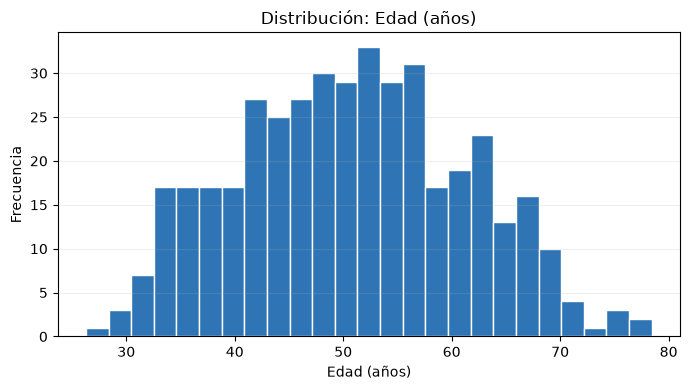

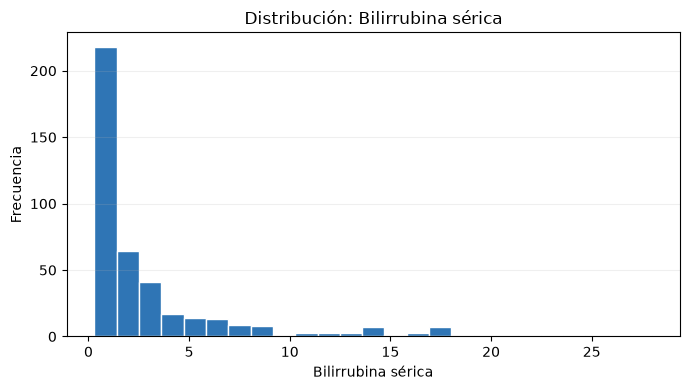

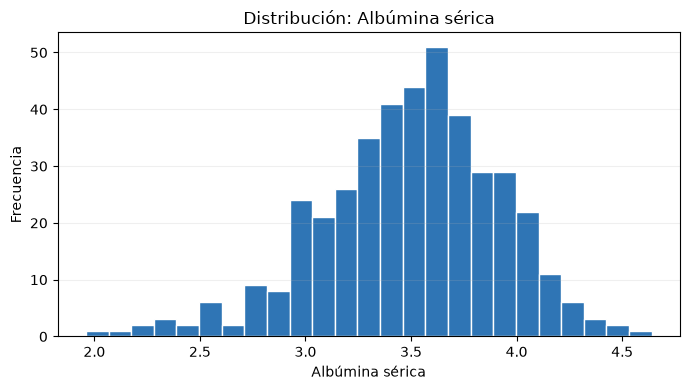

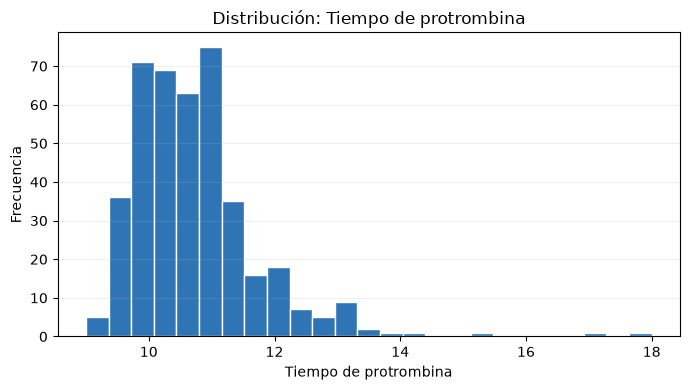

In [7]:
plot_df = df.copy()
if "Age" in plot_df.columns:
    plot_df["Age_years_EDA"] = pd.to_numeric(plot_df["Age"], errors="coerce") / 365.25
selected = [
    ("Age_years_EDA", "Edad (años)"),
    ("Bilirubin", "Bilirrubina sérica"),
    ("Albumin", "Albúmina sérica"),
    ("Prothrombin", "Tiempo de protrombina"),
]
existing = [(c, label) for c, label in selected if c in plot_df.columns]
for col, label in existing:
    values = pd.to_numeric(plot_df[col], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(values, bins=25, edgecolor="white", color="#2F75B5")
    ax.set(title=f"Distribución: {label}", xlabel=label, ylabel="Frecuencia")
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    fig.savefig(FIGURES / f"eda_distribucion_{col.lower()}.png", dpi=180)
    plt.show()

## 7. Variables predictoras propuestas para los modelos

In [8]:
X_candidate = clinical_predictors(df)
display(X_candidate.describe().T)
model_audit = pd.DataFrame({
    "variable_modelo": X_candidate.columns,
    "n_faltantes": [int(X_candidate[c].isna().sum()) for c in X_candidate.columns],
    "pct_faltantes": [float(X_candidate[c].isna().mean() * 100) for c in X_candidate.columns],
})
display(model_audit)
model_audit.to_csv(TABLES / "auditoria_predictores_modelo.csv", index=False, encoding="utf-8-sig")

print("Predictores modelados:", list(X_candidate.columns))
print("Fundamento: edad, bilirrubina, albúmina, tiempo de protrombina y edema, variables utilizadas en el modelo histórico de Mayo para PBC.")
print("Las transformaciones y la imputación se aplican dentro de cada pliegue de entrenamiento en el segundo notebook.")

,count,mean,std,min,25%,50%,75%,max
Age_years,418.0,50.741551,10.447214,26.277892,42.832307,51.000684,58.240931,78.439425
log_Bilirubin,418.0,0.571493,1.023798,-1.203973,-0.223144,0.336472,1.223775,3.332205
log_Albumin,418.0,1.244156,0.128155,0.672944,1.176344,1.261298,1.327075,1.534714
log_Prothrombin,416.0,2.369130,0.088312,2.197225,2.302585,2.360854,2.406945,2.890372
Edema_score,418.0,0.100478,0.253417,0.000000,0.000000,0.000000,0.000000,1.000000


,variable_modelo,n_faltantes,pct_faltantes
0,Age_years,0,0.000000
1,log_Bilirubin,0,0.000000
2,log_Albumin,0,0.000000
3,log_Prothrombin,2,0.478469
4,Edema_score,0,0.000000


Predictores modelados: ['Age_years', 'log_Bilirubin', 'log_Albumin', 'log_Prothrombin', 'Edema_score']
Fundamento: edad, bilirrubina, albúmina, tiempo de protrombina y edema, variables utilizadas en el modelo histórico de Mayo para PBC.
Las transformaciones y la imputación se aplican dentro de cada pliegue de entrenamiento en el segundo notebook.


## 8. Tabla de correspondencia para el análisis temporal

In [9]:
time, event, status_labels = survival_outcomes(df)
event_summary = pd.DataFrame({"Status": status_labels, "event_code": event}).value_counts().rename("n").reset_index()
event_summary["interpretacion"] = event_summary["event_code"].map({
    0: "Censura administrativa / finalización del seguimiento",
    1: "Fallecimiento (evento de interés)",
    2: "Trasplante (evento competitivo)",
})
display(event_summary)
event_summary.to_csv(TABLES / "codificacion_eventos.csv", index=False, encoding="utf-8-sig")

print(f"Rango temporal observado: {time.min():.0f} a {time.max():.0f} días")
print("Codificación: C=0, D=1, CL=2.")
print("No se imputan tiempos hipotéticos posteriores al trasplante.")

,Status,event_code,n,interpretacion
0,C,0,232,Censura administrativa / finalización del segu...
1,D,1,161,Fallecimiento (evento de interés)
2,CL,2,25,Trasplante (evento competitivo)


Rango temporal observado: 41 a 4795 días
Codificación: C=0, D=1, CL=2.
No se imputan tiempos hipotéticos posteriores al trasplante.


## 9. Conclusiones exploratorias que debe completar el equipo

No escribir conclusiones clínicas a partir de gráficos aislados. Tras revisar las salidas, anote: (1) variables con mayor proporción de faltantes; (2) equilibrio entre estados; (3) asimetrías o extremos importantes; (4) cualquier limitación de calidad que afecte la interpretación; y (5) qué se deberá explicar en el informe. Estas observaciones deben basarse en las tablas y gráficos generados durante la ejecución.